## TUGAS AKHIR KUALITAS UDARA KELOMPOK 4

**Judul Proyek**: Klasifikasi dan Monitoring Kualitas Udara Real-Time Berbasis Machine Learning (Baseline Decision Tree & KNN)

**Anggota Tim**:
1. MUHAMMAD RAIHAN AMMAR RIFFA'I - 230935607876 (Anggota)
2. REVANZA WILDAN PUTRA WARDANA - 230935605186 (Ketua)
3. RIDA FAIRUZ ZAHIRAH CAESAR - 230532601488 (Anggota)


In [12]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('muted')
print("Library pendukung Machine Learning & Visualisasi berhasil dimuat.")

Library pendukung Machine Learning & Visualisasi berhasil dimuat.


In [13]:
print("=== 1. LOADING DATASET SENSOR KUALITAS UDARA ===")
csv_path = 'AirQuality.csv'

if os.path.exists(csv_path):
    print(f"Dataset '{csv_path}' ditemukan! Memuat data sensor...")
    # Dataset UCI AirQuality menggunakan pemisah titik-koma (;) dan koma (,) untuk desimal
    df_raw = pd.read_csv(csv_path, sep=';', decimal=',')
    
    # 1. Menghapus kolom kosong akibat trailing semicolon (;; di akhir baris)
    df_raw = df_raw.loc[:, ~df_raw.columns.str.contains('^Unnamed')]
    df_raw = df_raw.dropna(how='all', axis=1).dropna(how='all', axis=0)
    
    # 2. Menangani nilai sentinel sensor error (-200) khas dataset instrumen lingkungan
    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns
    df_raw[numeric_cols] = df_raw[numeric_cols].replace(-200.0, np.nan)
    df_raw[numeric_cols] = df_raw[numeric_cols].replace(-200, np.nan)
    
    # 3. Mengambil fitur sensor inti dan menghapus missing values
    df_sensor = df_raw[['T', 'RH', 'PT08.S1(CO)']].dropna().copy()
    
    # 4. Memetakan ke variabel sensor IoT proyek:
    # T -> Suhu_DHT (°C), RH -> Kelembapan_DHT (%), PT08.S1(CO) -> MQ135 (PPM terkalibrasi)
    min_pt = df_sensor['PT08.S1(CO)'].min()
    max_pt = df_sensor['PT08.S1(CO)'].max()
    mq135_scaled = 100.0 + ((df_sensor['PT08.S1(CO)'] - min_pt) / (max_pt - min_pt)) * 800.0
    
    df = pd.DataFrame({
        'Suhu_DHT': df_sensor['T'].round(2),
        'Kelembapan_DHT': df_sensor['RH'].round(2),
        'MQ135': mq135_scaled.round(2)
    }).reset_index(drop=True)
    
    print(f"Dataset riil berhasil diproses: {df.shape[0]} baris observasi.")
else:
    print(f"File '{csv_path}' tidak ditemukan, membuat dataset simulasi sensor terkalibrasi...")
    np.random.seed(42)
    n = 1000
    suhu = np.random.uniform(18, 40, n)
    kelembapan = np.random.uniform(30, 90, n)
    mq135 = np.random.uniform(100, 900, n)
    
    # Penambahan noise/outlier & missing values untuk pengujian preprocessing
    suhu[10] = np.nan
    mq135[25] = 9999.0
    
    df = pd.DataFrame({
        'Suhu_DHT': suhu,
        'Kelembapan_DHT': kelembapan,
        'MQ135': mq135
    })

print(f"Ukuran Data Awal: {df.shape}")
df.head()

=== 1. LOADING DATASET SENSOR KUALITAS UDARA ===
Dataset 'AirQuality.csv' ditemukan! Memuat data sensor...
Dataset riil berhasil diproses: 8991 baris observasi.
Ukuran Data Awal: (8991, 3)


,Suhu_DHT,Kelembapan_DHT,MQ135
0,13.6,48.9,509.48
1,13.3,47.7,470.42
2,11.9,54.0,533.60
3,11.0,60.0,518.66
4,11.2,59.6,458.94


In [14]:
print("=== 2. PEMBERSIHAN DATA SENSOR ===")

# 1. Handling Missing Values
missing_count = df.isnull().sum().sum()
print(f"Jumlah Missing Values Terdeteksi: {missing_count}")
df = df.dropna().reset_index(drop=True)

# 2. Handling Outliers / Noise (Filter IQR dengan Reset Index)
def clean_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

for col in ['Suhu_DHT', 'Kelembapan_DHT', 'MQ135']:
    df = clean_outliers(df, col)

# Reset indeks agar kontinu setelah penghapusan baris outlier
df = df.reset_index(drop=True)

print(f"Ukuran Data Setelah Cleaning: {df.shape}")
df.describe().round(2)

=== 2. PEMBERSIHAN DATA SENSOR ===
Jumlah Missing Values Terdeteksi: 0
Ukuran Data Setelah Cleaning: (8870, 3)


,Suhu_DHT,Kelembapan_DHT,MQ135
count,8870.00,8870.00,8870.00
mean,18.32,49.15,354.88
std,8.86,17.36,117.03
min,-1.90,9.20,100.00
25%,11.80,35.70,265.40
50%,17.80,49.40,336.61
75%,24.48,62.50,430.22
max,43.10,88.70,686.93


In [15]:
print("=== 3. GENERATING LABEL TARGET (STANDAR ISPU & IOT) ===")

# Aturan klasifikasi berbasis standar konsentrasi gas berbahaya & kenyamanan lingkungan:
# 1. MQ-135 < 350 PPM: Kualitas Baik (kecuali suhu sangat ekstrem > 38°C)
# 2. 350 <= MQ-135 < 650 PPM: Kualitas Sedang (jika suhu > 36°C & kelembapan > 85% dinaikkan ke Tidak Sehat)
# 3. MQ-135 >= 650 PPM: Tidak Sehat (konsentrasi gas berbahaya tinggi)
def generate_label(row):
    gas = row['MQ135']
    suhu = row['Suhu_DHT']
    kelembapan = row['Kelembapan_DHT']
    
    if gas >= 650:
        return 'Tidak Sehat'
    elif gas >= 350:
        if suhu > 36 and kelembapan > 85:
            return 'Tidak Sehat'
        return 'Sedang'
    else:
        if suhu > 38:
            return 'Sedang'
        return 'Baik'

df['Kategori'] = df.apply(generate_label, axis=1)

print("Distribusi Frekuensi Kelas Kualitas Udara:")
print(df['Kategori'].value_counts())
df.head()

=== 3. GENERATING LABEL TARGET (STANDAR ISPU & IOT) ===
Distribusi Frekuensi Kelas Kualitas Udara:
Kategori
Baik           4728
Sedang         4058
Tidak Sehat      84
Name: count, dtype: int64


,Suhu_DHT,Kelembapan_DHT,MQ135,Kategori
0,13.6,48.9,509.48,Sedang
1,13.3,47.7,470.42,Sedang
2,11.9,54.0,533.60,Sedang
3,11.0,60.0,518.66,Sedang
4,11.2,59.6,458.94,Sedang


In [16]:
print("=== 4. SPLITTING & FEATURE SCALING ===")

# Separasi Fitur (X) dan Target (y)
X = df[['Suhu_DHT', 'Kelembapan_DHT', 'MQ135']]
y = df['Kategori']

# Train-Test Split (80% Pelatihan, 20% Pengujian dengan Stratified Sampling)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling khusus untuk algoritma berbasis jarak (KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling berhasil dilakukan dengan StandardScaler.")
print(f"Jumlah Data Latih (Train): {X_train.shape[0]} | Data Uji (Test): {X_test.shape[0]}")

=== 4. SPLITTING & FEATURE SCALING ===
Feature scaling berhasil dilakukan dengan StandardScaler.
Jumlah Data Latih (Train): 7096 | Data Uji (Test): 1774


In [17]:
print("=== 5. TRAINING MODEL BASELINE (DECISION TREE & KNN) ===")

# 1. Model Baseline Decision Tree (interpretable, menggunakan fitur asli)
model_dt = DecisionTreeClassifier(max_depth=4, random_state=42)
model_dt.fit(X_train, y_train)

# 2. Model Baseline K-Nearest Neighbors (menggunakan data terstandarisasi)
model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(X_train_scaled, y_train)

print("Pelatihan model Decision Tree (max_depth=4) dan KNN (k=5) berhasil diselesaikan.")

=== 5. TRAINING MODEL BASELINE (DECISION TREE & KNN) ===
Pelatihan model Decision Tree (max_depth=4) dan KNN (k=5) berhasil diselesaikan.


=== 6. EVALUASI MODEL BASELINE KOMPARATIF ===
Akurasi Baseline Decision Tree : 100.00% | F1-Score: 100.00%
Akurasi Baseline KNN           : 98.08% | F1-Score: 98.06%

--- Classification Report (Decision Tree) ---
              precision    recall  f1-score   support

        Baik       1.00      1.00      1.00       946
      Sedang       1.00      1.00      1.00       811
 Tidak Sehat       1.00      1.00      1.00        17

    accuracy                           1.00      1774
   macro avg       1.00      1.00      1.00      1774
weighted avg       1.00      1.00      1.00      1774


--- Classification Report (KNN) ---
              precision    recall  f1-score   support

        Baik       0.98      0.99      0.98       946
      Sedang       0.98      0.98      0.98       811
 Tidak Sehat       1.00      0.71      0.83        17

    accuracy                           0.98      1774
   macro avg       0.99      0.89      0.93      1774
weighted avg       0.98      0.98      0.98

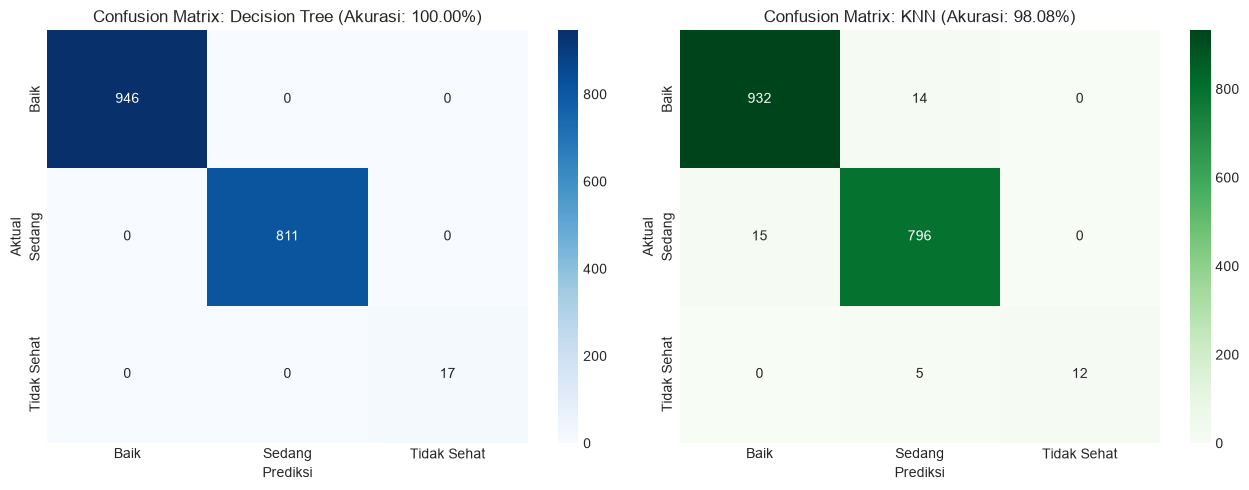

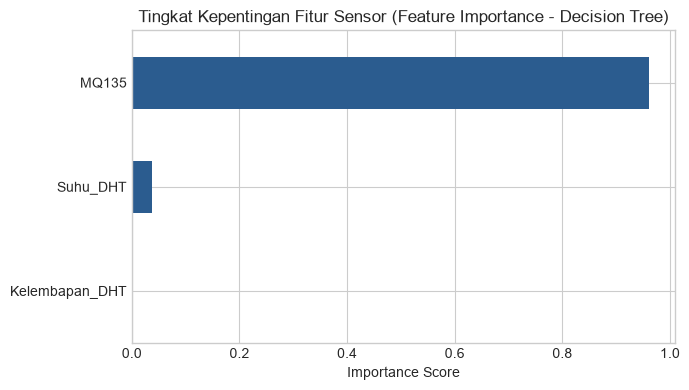

In [18]:
print("=== 6. EVALUASI MODEL BASELINE KOMPARATIF ===")

# Prediksi pada set data uji
y_pred_dt = model_dt.predict(X_test)
y_pred_knn = model_knn.predict(X_test_scaled)

acc_dt = accuracy_score(y_test, y_pred_dt) * 100
acc_knn = accuracy_score(y_test, y_pred_knn) * 100
f1_dt = f1_score(y_test, y_pred_dt, average='weighted') * 100
f1_knn = f1_score(y_test, y_pred_knn, average='weighted') * 100

print(f"Akurasi Baseline Decision Tree : {acc_dt:.2f}% | F1-Score: {f1_dt:.2f}%")
print(f"Akurasi Baseline KNN           : {acc_knn:.2f}% | F1-Score: {f1_knn:.2f}%\n")

print("--- Classification Report (Decision Tree) ---")
print(classification_report(y_test, y_pred_dt))

print("\n--- Classification Report (KNN) ---")
print(classification_report(y_test, y_pred_knn))

# Visualisasi Confusion Matrix Berdampingan (Decision Tree vs KNN)
classes = sorted(list(y.unique()))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=classes)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=classes, yticklabels=classes)
axes[0].set_title(f'Confusion Matrix: Decision Tree (Akurasi: {acc_dt:.2f}%)')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

cm_knn = confusion_matrix(y_test, y_pred_knn, labels=classes)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=classes, yticklabels=classes)
axes[1].set_title(f'Confusion Matrix: KNN (Akurasi: {acc_knn:.2f}%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.savefig('confusion_matrix_baseline.png', dpi=150)
plt.show()

# Visualisasi Feature Importance Decision Tree
plt.figure(figsize=(7, 4))
feat_imp = pd.Series(model_dt.feature_importances_, index=X.columns).sort_values(ascending=True)
feat_imp.plot(kind='barh', color='#2b5c8f')
plt.title('Tingkat Kepentingan Fitur Sensor (Feature Importance - Decision Tree)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('feature_importance_dt.png', dpi=150)
plt.show()

In [19]:
print("=== 7. EXPORT MODEL ARTIFACT UNTUK DEPLOYMENT IOT ===")

# Serialisasi model dan scaler menggunakan joblib untuk integrasi mikrokontroler/backend
joblib.dump(model_dt, 'model_decision_tree.joblib')
joblib.dump(model_knn, 'model_knn.joblib')
joblib.dump(scaler, 'scaler.joblib')

print("Artefak model berhasil diekspor:")
print(" - model_decision_tree.joblib")
print(" - model_knn.joblib")
print(" - scaler.joblib")

=== 7. EXPORT MODEL ARTIFACT UNTUK DEPLOYMENT IOT ===
Artefak model berhasil diekspor:
 - model_decision_tree.joblib
 - model_knn.joblib
 - scaler.joblib


In [20]:
print("=== 8. INFERENCE PIPELINE (PREDIKSI SENSOR REAL-TIME DENGAN VALIDASI) ===")

def predict_air_quality(suhu_val, kelembapan_val, mq135_val, model_type='dt'):
    """
    Fungsi inferensi untuk memprediksi data sensor baru dengan validasi dan confidence score.
    
    Parameter:
        suhu_val (float): Suhu lingkungan dari sensor DHT (°C)
        kelembapan_val (float): Kelembapan relatif dari sensor DHT (%)
        mq135_val (float): Konsentrasi gas dari sensor MQ-135 (PPM)
        model_type (str): Pilihan model ('dt' untuk Decision Tree, 'knn' untuk KNN)
        
    Returns:
        dict: Hasil prediksi, confidence score, dan rekomendasi kesehatan.
    """
    # Validasi batas fisik sensor
    if not (-20 <= suhu_val <= 60):
        return {"error": f"Nilai Suhu ({suhu_val}°C) di luar rentang pembacaan wajar (-20 s/d 60°C)."}
    if not (0 <= kelembapan_val <= 100):
        return {"error": f"Nilai Kelembapan ({kelembapan_val}%) di luar rentang valid (0 s/d 100%)."}
    if not (0 <= mq135_val <= 2000):
        return {"error": f"Nilai MQ-135 ({mq135_val} PPM) di luar rentang deteksi (0 s/d 2000 PPM)."}
        
    input_data = pd.DataFrame([[suhu_val, kelembapan_val, mq135_val]], 
                              columns=['Suhu_DHT', 'Kelembapan_DHT', 'MQ135'])
    
    if model_type.lower() == 'knn':
        input_data_scaled = scaler.transform(input_data)
        pred = model_knn.predict(input_data_scaled)[0]
        proba = np.max(model_knn.predict_proba(input_data_scaled)) * 100
    else:
        pred = model_dt.predict(input_data)[0]
        proba = np.max(model_dt.predict_proba(input_data)) * 100
        
    saran_dict = {
        'Baik': 'Kualitas udara sangat baik dan menyegarkan. Aman untuk beraktivitas luar ruangan.',
        'Sedang': 'Kualitas udara moderat. Disarankan menjaga ventilasi ruangan tetap lancar.',
        'Tidak Sehat': 'PERINGATAN: Kualitas udara tercemar! Hidupkan exhaust fan/purifier dan gunakan masker.'
    }
        
    return {
        'Status': pred,
        'Confidence': f"{proba:.1f}%",
        'Model': 'KNN' if model_type.lower() == 'knn' else 'Decision Tree',
        'Rekomendasi': saran_dict.get(pred, '-')
    }

# Pengujian Sampel Real-Time
test_samples = [
    (25.0, 50.0, 200.0), # Ekspektasi: Baik
    (29.0, 65.0, 480.0), # Ekspektasi: Sedang
    (34.0, 80.0, 750.0)  # Ekspektasi: Tidak Sehat
]

print("Hasil Uji Coba Fungsi Inferensi Real-Time:")
for s, k, m in test_samples:
    res_dt = predict_air_quality(s, k, m, model_type='dt')
    res_knn = predict_air_quality(s, k, m, model_type='knn')
    print(f"Input: Suhu={s}°C, Humidity={k}%, MQ135={m} PPM")
    print(f"  [DT ] Prediksi: {res_dt['Status']} (Keyakinan: {res_dt['Confidence']})")
    print(f"  [KNN] Prediksi: {res_knn['Status']} (Keyakinan: {res_knn['Confidence']})")
    print(f"  Rekomendasi: {res_dt['Rekomendasi']}\n")

=== 8. INFERENCE PIPELINE (PREDIKSI SENSOR REAL-TIME DENGAN VALIDASI) ===
Hasil Uji Coba Fungsi Inferensi Real-Time:
Input: Suhu=25.0°C, Humidity=50.0%, MQ135=200.0 PPM
  [DT ] Prediksi: Baik (Keyakinan: 100.0%)
  [KNN] Prediksi: Baik (Keyakinan: 100.0%)
  Rekomendasi: Kualitas udara sangat baik dan menyegarkan. Aman untuk beraktivitas luar ruangan.

Input: Suhu=29.0°C, Humidity=65.0%, MQ135=480.0 PPM
  [DT ] Prediksi: Sedang (Keyakinan: 100.0%)
  [KNN] Prediksi: Sedang (Keyakinan: 100.0%)
  Rekomendasi: Kualitas udara moderat. Disarankan menjaga ventilasi ruangan tetap lancar.

Input: Suhu=34.0°C, Humidity=80.0%, MQ135=750.0 PPM
  [DT ] Prediksi: Tidak Sehat (Keyakinan: 100.0%)
  [KNN] Prediksi: Tidak Sehat (Keyakinan: 100.0%)
  Rekomendasi: PERINGATAN: Kualitas udara tercemar! Hidupkan exhaust fan/purifier dan gunakan masker.



=== PENGUJIAN PROOF-OF-CONCEPT: 100 DATA DUMMY BARU ===
[1] Model Decision Tree, KNN, dan Scaler berhasil dimuat.
[2] 100 data sensor dummy baru berhasil dibangkitkan. Ukuran: (100, 3)

--- CONTOH 10 DATA PERTAMA HASIL PREDIKSI ---
   Suhu_DHT  Kelembapan_DHT  MQ135  Prediksi_DT Prediksi_KNN  Sepakat
0      32.5            84.3  862.1  Tidak Sehat  Tidak Sehat     True
1      29.8            57.7  472.6       Sedang       Sedang     True
2      26.7            68.8  440.3       Sedang       Sedang     True
3      27.8            68.8  485.5       Sedang       Sedang     True
4      32.1            61.4  394.3       Sedang       Sedang     True
5      24.0            53.7  251.5         Baik         Baik     True
6      25.8            47.3  169.7         Baik         Baik     True
7      31.9            76.9  890.8  Tidak Sehat  Tidak Sehat     True
8      22.7            47.9  286.4         Baik         Baik     True
9      25.6            52.8  234.0         Baik         Baik     Tru

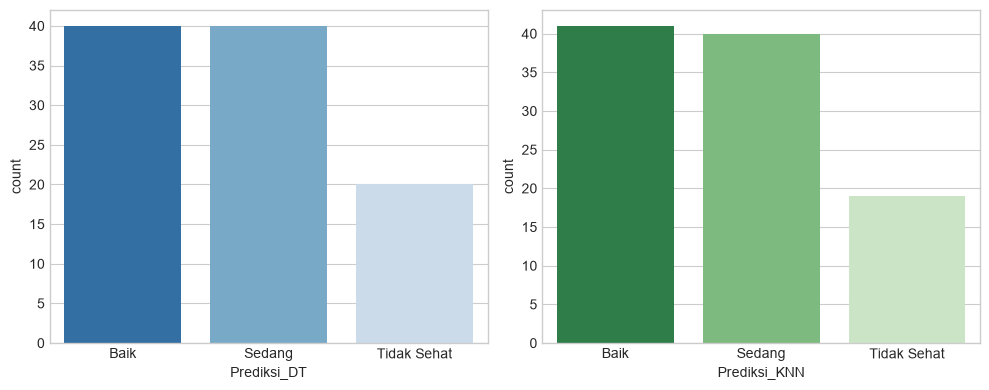

In [21]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=== PENGUJIAN PROOF-OF-CONCEPT: 100 DATA DUMMY BARU ===")

# -------------------------------------------------------------------------
# LANGKAH 1: MEMUAT MODEL & SCALER YANG SUDAH DILATIH SEBELUMNYA
# -------------------------------------------------------------------------
model_dt = joblib.load('model_decision_tree.joblib')
model_knn = joblib.load('model_knn.joblib')
scaler = joblib.load('scaler.joblib')
print("[1] Model Decision Tree, KNN, dan Scaler berhasil dimuat.")

# -------------------------------------------------------------------------
# LANGKAH 2: GENERATE 100 BARIS DATA DUMMY DENGAN VARIASI KONDISI REALISTIS
# -------------------------------------------------------------------------
# Kita variasikan ke dalam 3 kondisi lingkungan:
# a. 40 sampel: Kondisi Bersih (Suhu 20-28°C, RH 40-65%, MQ135 120-330 PPM)
# b. 40 sampel: Kondisi Sedang  (Suhu 26-33°C, RH 50-75%, MQ135 370-620 PPM)
# c. 20 sampel: Kondisi Buruk   (Suhu 29-38°C, RH 60-90%, MQ135 660-920 PPM)
np.random.seed(123)  # Seed acak independen

suhu_baru = np.concatenate([
    np.random.uniform(20.0, 28.0, 40),
    np.random.uniform(26.0, 33.0, 40),
    np.random.uniform(29.0, 38.0, 20)
]).round(1)

kelembapan_baru = np.concatenate([
    np.random.uniform(40.0, 65.0, 40),
    np.random.uniform(50.0, 75.0, 40),
    np.random.uniform(60.0, 90.0, 20)
]).round(1)

mq135_baru = np.concatenate([
    np.random.uniform(120.0, 330.0, 40),
    np.random.uniform(370.0, 620.0, 40),
    np.random.uniform(660.0, 920.0, 20)
]).round(1)

df_test_100 = pd.DataFrame({
    'Suhu_DHT': suhu_baru,
    'Kelembapan_DHT': kelembapan_baru,
    'MQ135': mq135_baru
})

# Acak urutan baris agar menyerupai kedatangan aliran data sensor real-time
df_test_100 = df_test_100.sample(frac=1.0, random_state=42).reset_index(drop=True)
print(f"[2] 100 data sensor dummy baru berhasil dibangkitkan. Ukuran: {df_test_100.shape}")

# -------------------------------------------------------------------------
# LANGKAH 3: PREDIKSI MASSAL (BATCH INFERENCE)
# -------------------------------------------------------------------------
# A. Prediksi Decision Tree (Langsung menggunakan fitur asli)
pred_dt = model_dt.predict(df_test_100)
conf_dt = np.max(model_dt.predict_proba(df_test_100), axis=1) * 100

# B. Prediksi KNN (Wajib melewati scaler.transform)
df_test_scaled = scaler.transform(df_test_100)
pred_knn = model_knn.predict(df_test_scaled)
conf_knn = np.max(model_knn.predict_proba(df_test_scaled), axis=1) * 100

# -------------------------------------------------------------------------
# LANGKAH 4: MENGGABUNGKAN DAN MENGEVALUASI HASIL KONSENSUS
# -------------------------------------------------------------------------
df_hasil = df_test_100.copy()
df_hasil['Prediksi_DT'] = pred_dt
df_hasil['Keyakinan_DT (%)'] = conf_dt.round(1)
df_hasil['Prediksi_KNN'] = pred_knn
df_hasil['Keyakinan_KNN (%)'] = conf_knn.round(1)

# Cek apakah kedua model sepakat pada prediksi yang sama
df_hasil['Sepakat'] = (df_hasil['Prediksi_DT'] == df_hasil['Prediksi_KNN'])

print("\n--- CONTOH 10 DATA PERTAMA HASIL PREDIKSI ---")
print(df_hasil[['Suhu_DHT', 'Kelembapan_DHT', 'MQ135', 'Prediksi_DT', 'Prediksi_KNN', 'Sepakat']].head(10))

# Rekapitulasi jumlah tiap kelas yang diprediksi
print("\n--- REKAPITULASI HASIL DARI 100 DATA UJI ---")
rekap = pd.DataFrame({
    'Decision Tree': df_hasil['Prediksi_DT'].value_counts(),
    'KNN': df_hasil['Prediksi_KNN'].value_counts()
}).fillna(0).astype(int)
print(rekap)

konsensus = (df_hasil['Sepakat'].sum() / len(df_hasil)) * 100
print(f"\nTingkat Kesepakatan Model (Decision Tree vs KNN): {konsensus:.1f}%")

# -------------------------------------------------------------------------
# LANGKAH 5: EKSPOR HASIL KE FILE CSV & VISUALISASI
# -------------------------------------------------------------------------
df_hasil.to_csv('hasil_uji_100_data_dummy.csv', index=False)
print("\n[OK] Hasil lengkap tersimpan di file: 'hasil_uji_100_data_dummy.csv'")

# Visualisasi perbandingan distribusi prediksi
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Tambahkan hue dan legend=False
sns.countplot(
    data=df_hasil,
    x='Prediksi_DT',
    hue='Prediksi_DT',
    order=['Baik', 'Sedang', 'Tidak Sehat'],
    palette='Blues',
    legend=False,
    ax=axes[0],
)

sns.countplot(
    data=df_hasil,
    x='Prediksi_KNN',
    hue='Prediksi_KNN',
    order=['Baik', 'Sedang', 'Tidak Sehat'],
    palette='Greens',
    legend=False,
    ax=axes[1],
)

plt.tight_layout()
plt.show()